### using Solar_data\Filtered_Train_dataset_v2.xlsx dataset create a Multi-regression model to with training (80%) and test (20%) for predict Solar Irradiance using parameter (Ambient Temperature, Relative Humidity, Differerntial Temperature and Light Intensity).

In [22]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.preprocessing import StandardScaler

In [23]:
# 1. Load the dataset
# Ensure your column names in the Excel file match these exactly, or update the strings below.
filtered_path = r'Solar_data\Filtered_Train_dataset_v2.xlsx'
df = pd.read_excel(filtered_path)

In [24]:
df.head()

,Date,Time,Solar_Power_Meter,Ambient_temp,Relative_humidity,Black(T2),White(T3),panel_Temp,T2-T3,Light_Intensity,INA_current
0,2026-08-29,13:55:37,171,37.5,57.1,46.56,41.50,48.88,5.06,2356,15.4
1,2026-08-29,14:00:37,136,37.1,57.9,44.00,40.06,45.69,3.94,2063,14.5
2,2026-08-29,14:05:37,106,37.0,58.6,42.25,38.81,43.69,3.44,1733,12.3
3,2026-08-29,14:10:37,98,36.7,58.8,40.38,37.56,41.94,2.82,1457,10.3
4,2026-08-29,14:15:37,124,36.5,59.7,39.75,37.00,40.75,2.75,1704,11.5


In [25]:
df.describe()

,Solar_Power_Meter,Ambient_temp,Relative_humidity,Black(T2),White(T3),panel_Temp,T2-T3,Light_Intensity,INA_current
count,117.000000,117.000000,117.000000,117.000000,117.000000,117.000000,117.000000,117.000000,117.000000
mean,600.145299,37.182051,54.860684,63.267607,49.414615,63.461368,13.583761,7713.957265,31.684615
std,305.209574,1.929919,6.284216,12.401722,6.641089,11.231497,5.720835,3513.969034,9.865724
min,70.000000,32.900000,43.000000,39.310000,36.250000,40.750000,2.750000,1457.000000,10.300000
25%,238.000000,35.400000,51.100000,48.940000,42.560000,54.190000,7.250000,3954.000000,24.300000
50%,769.000000,37.900000,53.100000,71.060000,52.560000,68.560000,17.190000,9485.000000,34.600000
75%,852.000000,38.600000,57.900000,73.190000,54.940000,72.500000,18.190000,10516.000000,39.200000
max,1080.000000,39.900000,71.300000,77.000000,57.440000,77.750000,20.500000,13474.000000,51.200000


In [26]:
features = ['Ambient_temp', 'Relative_humidity', 'T2-T3', 'Light_Intensity']
target = 'Solar_Power_Meter'

In [27]:
df_clean = df.dropna(subset=features + [target])

X = df_clean[features]
y = df_clean[target]

# 2. Split the data: 80% for training, 20% for testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
print(f"Training set size: {X_train.shape[0]} samples")
print(f"Testing set size: {X_test.shape[0]} samples")
# print(f"Training set shape: {X_train.shape}")
# print(f"Testing set shape: {X_test.shape}")

Training set size: 93 samples
Testing set size: 24 samples


In [28]:
# 3. Initialize and train the MLR model
mlr_model = LinearRegression()
mlr_model.fit(X_train, y_train)

# 4. Generate predictions on the 20% unseen test data
y_pred = mlr_model.predict(X_test)

# 5. Evaluate the model's accuracy
r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)
mbe = np.mean(y_pred - y_test)

In [29]:
# Print out the evaluation metrics
print("=== Model Evaluation ===")
print(f"R2: {r2:.4f}")
print(f"RMSE: {rmse:.2f} W/m2")
print(f"MAE: {mae:.2f} W/m2")
print(f"MBE: {mbe:.2f} W/m2\n")

# Print the model parameters (equation weights)
print("=== Trained Model Parameters ===")
print(f"Intercept: {mlr_model.intercept_:.4f}")
for feature, coef in zip(features, mlr_model.coef_):
    print(f"{feature} Weight: {coef:.4f}")

=== Model Evaluation ===
R2: 0.9833
RMSE: 38.22 W/m2
MAE: 33.17 W/m2
MBE: 2.99 W/m2

=== Trained Model Parameters ===
Intercept: -522.6023
Ambient_temp Weight: 10.0854
Relative_humidity Weight: 1.3649
T2-T3 Weight: 22.1962
Light_Intensity Weight: 0.0482


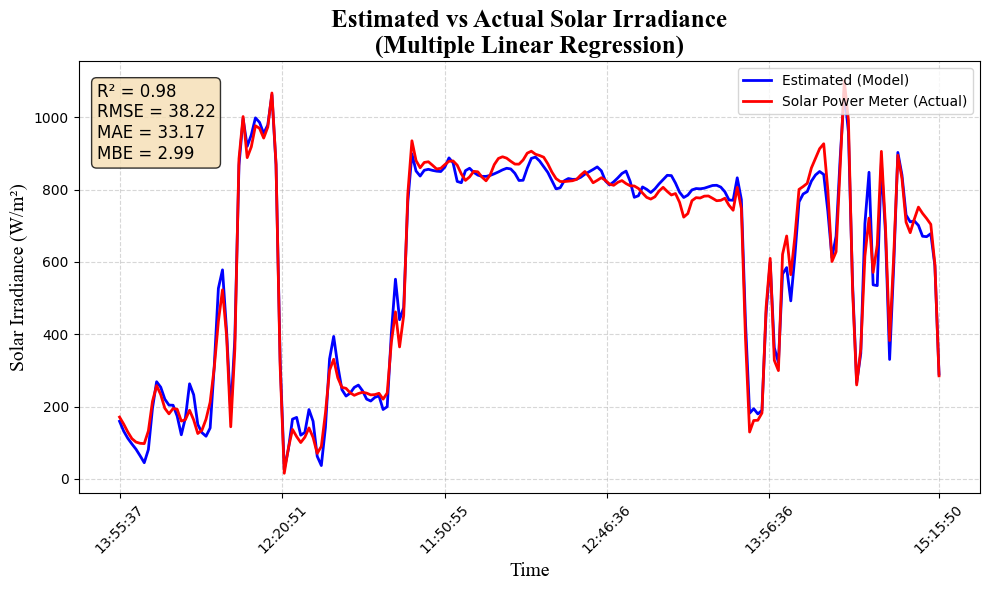

In [30]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.interpolate import make_interp_spline

# 1. Generate estimated values for the entire cleaned dataset using the trained Sklearn model
df_clean['Estimated_Irradiance'] = mlr_model.predict(df_clean[features])

# 2. Define the plot_smooth helper function based on your example
def plot_smooth(df, x, y, ax, n_points=200, color='blue', label=''):
    # Use numeric indices for smooth interpolation
    x_indices = np.arange(len(df))
    y_values = df[y].values
    
    # Create spline interpolation
    spl = make_interp_spline(x_indices, y_values, k=3)
    x_smooth = np.linspace(x_indices.min(), x_indices.max(), n_points)
    y_smooth = spl(x_smooth)
    
    ax.plot(x_smooth, y_smooth, color=color, label=label, linewidth=2)
    
    # Optional: Map a few specific time labels to the X-axis for context
    if x in df.columns:
        tick_positions = np.linspace(0, len(df)-1, 6).astype(int)
        ax.set_xticks(tick_positions)
        ax.set_xticklabels(df[x].iloc[tick_positions].astype(str), rotation=45)
        
    return ax

# 3. Create the plot using your specific layout and formatting
fig, axes = plt.subplots(1, 1, figsize=(10, 6))
4
# Subplot 1: Estimate Total Solar vs Actual
ax1 = axes
ax1 = plot_smooth(df_clean, x='Time', y='Estimated_Irradiance', ax=ax1, n_points=200, color='blue', label='Estimated (Model)')
ax1 = plot_smooth(df_clean, x='Time', y='Solar_Power_Meter', ax=ax1, n_points=200, color='red', label='Solar Power Meter (Actual)')

ax1.set_xlabel('Time', fontsize=14, fontname='Times New Roman')
ax1.set_ylabel('Solar Irradiance (W/m²)', fontsize=14, fontname='Times New Roman')
ax1.set_title('Estimated vs Actual Solar Irradiance\n(Multiple Linear Regression)', fontsize=18, fontweight='bold', fontname='Times New Roman')

# Insert text box with metrics from your notebook evaluation
# Using the variables r2, rmse, mae, mbe defined earlier in your notebook
ax1.text(0.02, 0.95, f'R² = {r2:.2f}\nRMSE = {rmse:.2f}\nMAE = {mae:.2f}\nMBE = {mbe:.2f}', 
         transform=ax1.transAxes, verticalalignment='top', 
         bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8), fontsize=12)

ax1.grid(True, linestyle='--', alpha=0.5)
#ax1.text(0.001, 1.1, '(a)', transform=ax1.transAxes, fontsize=20, fontweight='bold', va='top')
ax1.legend(loc='upper right')

plt.tight_layout()
plt.savefig("total_solar_comparison.png", dpi=300, bbox_inches='tight')
plt.show()